# BITS Pilani - M.Tech (AIML)
## Machine Learning - Assignment 2
### Classification Models on Breast Cancer Wisconsin Dataset
---
**Dataset:** Breast Cancer Wisconsin (Diagnostic) - UCI / sklearn  
**Features:** 30  
**Instances:** 569  
**Task:** Binary Classification (Malignant vs Benign)

## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.pipeline import make_pipeline

# Dataset
from sklearn.datasets import load_breast_cancer

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print('All libraries imported successfully!')


All libraries imported successfully!


## Step 2: Load and Explore Dataset

In [2]:
# Load Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print('Dataset Shape:', df.shape)
print('\nFeature Names:', list(data.feature_names))
print('\nTarget Names:', list(data.target_names))
print('\nClass Distribution:')
print(df['target'].value_counts())
print('\n0 = Malignant, 1 = Benign')


Dataset Shape: (569, 31)

Feature Names: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension'), np.str_('radius error'), np.str_('texture error'), np.str_('perimeter error'), np.str_('area error'), np.str_('smoothness error'), np.str_('compactness error'), np.str_('concavity error'), np.str_('concave points error'), np.str_('symmetry error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry'), np.str_('worst fractal dimension')]

Target Names: [np.str_('malignant'), np.str_('benign')]

Class Distribution:
target
1    357
0    212
Name: coun

In [3]:
# Display first few rows
df.head()


   mean radius  mean texture  ...  worst fractal dimension  target
0        17.99         10.38  ...                  0.11890       0
1        20.57         17.77  ...                  0.08902       0
2        19.69         21.25  ...                  0.08758       0
3        11.42         20.38  ...                  0.17300       0
4        20.29         14.34  ...                  0.07678       0

[5 rows x 31 columns]


In [4]:
# Basic Statistics
df.describe()


       mean radius  mean texture  ...  worst fractal dimension      target
count   569.000000    569.000000  ...               569.000000  569.000000
mean     14.127292     19.289649  ...                 0.083946    0.627417
std       3.524049      4.301036  ...                 0.018061    0.483918
min       6.981000      9.710000  ...                 0.055040    0.000000
25%      11.700000     16.170000  ...                 0.071460    0.000000
50%      13.370000     18.840000  ...                 0.080040    1.000000
75%      15.780000     21.800000  ...                 0.092080    1.000000
max      28.110000     39.280000  ...                 0.207500    1.000000

[8 rows x 31 columns]


In [5]:
# Check for missing values
print('Missing Values per Column:')
print(df.isnull().sum())
print('\nTotal Missing Values:', df.isnull().sum().sum())


Missing Values per Column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Total Missing Values: 0


## Step 3: Exploratory Data Analysis (EDA)

cell_9:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


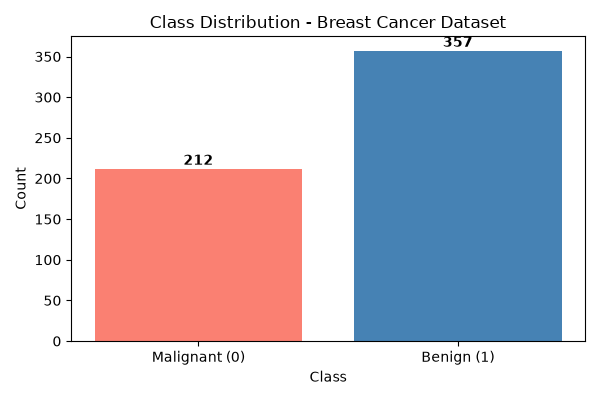

In [6]:
# Class Distribution Plot
plt.figure(figsize=(6, 4))
class_counts = df['target'].value_counts().reindex([0, 1])
plt.bar(['Malignant (0)', 'Benign (1)'], class_counts.values, color=['salmon', 'steelblue'])
plt.title('Class Distribution - Breast Cancer Dataset')
plt.xlabel('Class')
plt.ylabel('Count')
for i, v in enumerate(class_counts.values):
    plt.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


cell_10:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


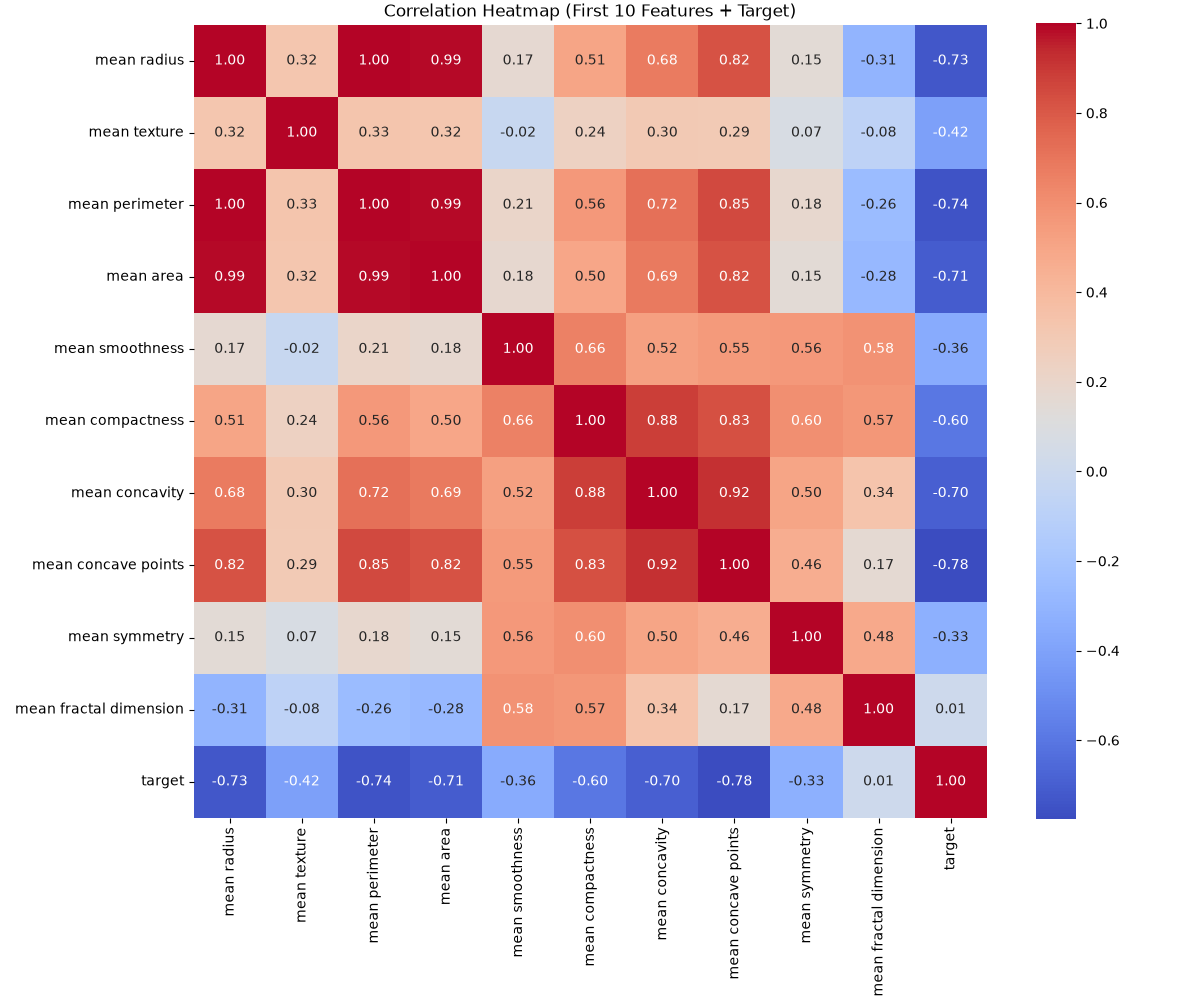

In [7]:
# Correlation Heatmap (first 10 features for readability)
plt.figure(figsize=(12, 10))
corr_cols = list(data.feature_names[:10]) + ['target']
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Heatmap (First 10 Features + Target)')
plt.tight_layout()
plt.show()


cell_11:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


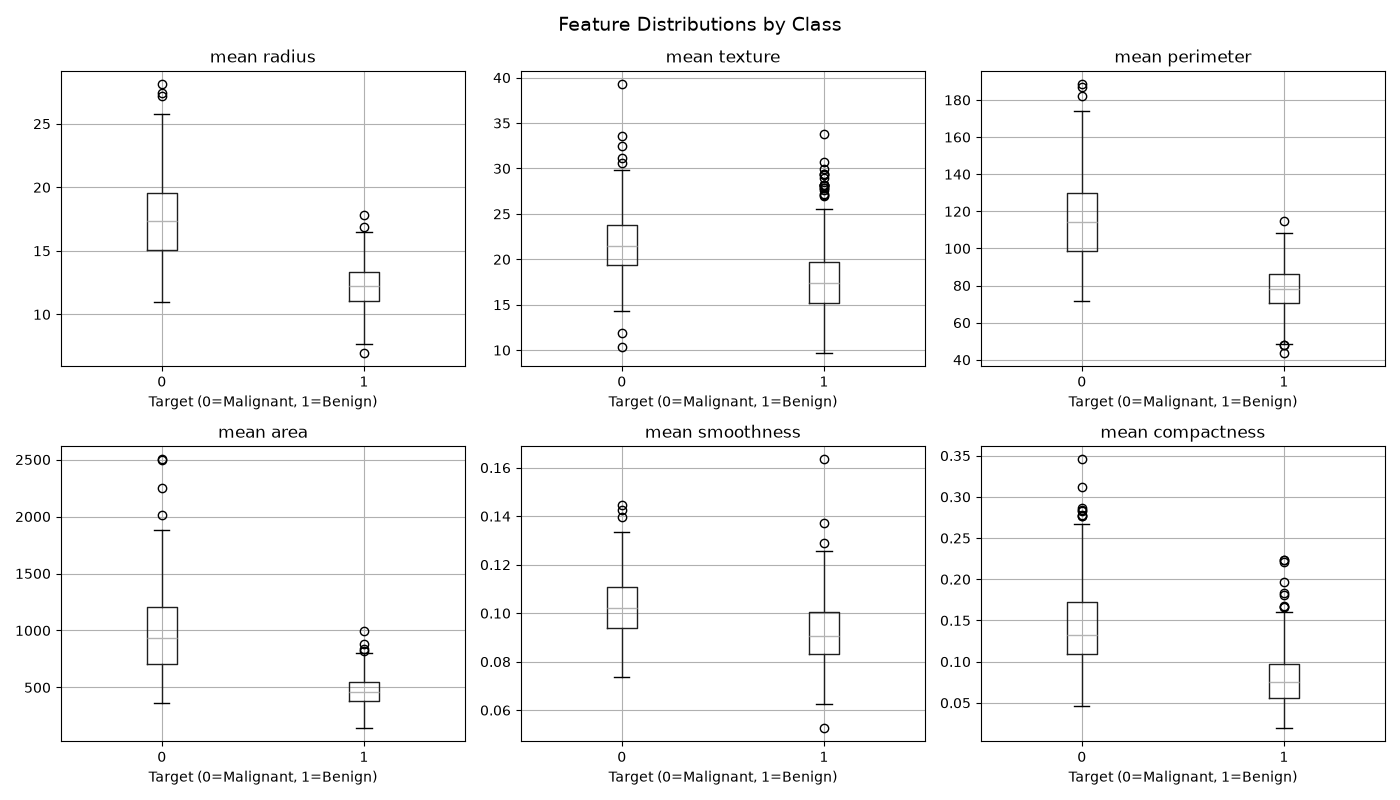

In [8]:
# Feature Distribution - Boxplot for top 6 features
top_features = ['mean radius', 'mean texture', 'mean perimeter',
                'mean area', 'mean smoothness', 'mean compactness']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, feat in enumerate(top_features):
    df.boxplot(column=feat, by='target', ax=axes[i])
    axes[i].set_title(feat)
    axes[i].set_xlabel('Target (0=Malignant, 1=Benign)')
plt.suptitle('Feature Distributions by Class', fontsize=14)
plt.tight_layout()
plt.show()


## Step 4: Data Preprocessing

In [9]:
# Separate Features and Target
X = df.drop('target', axis=1)
y = df['target']

print('Feature Matrix Shape:', X.shape)
print('Target Vector Shape:', y.shape)


Feature Matrix Shape: (569, 30)
Target Vector Shape: (569,)


In [10]:
# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training Set Size:', X_train.shape)
print('Test Set Size:', X_test.shape)
print('\nTraining Class Distribution:')
print(y_train.value_counts())
print('\nTest Class Distribution:')
print(y_test.value_counts())


Training Set Size: (455, 30)
Test Set Size: (114, 30)

Training Class Distribution:
target
1    285
0    170
Name: count, dtype: int64

Test Class Distribution:
target
1    72
0    42
Name: count, dtype: int64


In [11]:
# Each model below includes StandardScaler in its saved pipeline.
# Scaling is fitted only on training data during pipeline.fit().
print('Preprocessing is included in each model pipeline.')


Preprocessing is included in each model pipeline.


In [12]:
# Save test data as CSV for Streamlit app
test_df = X_test.copy()
test_df['target'] = y_test.values
test_df.to_csv('test_data.csv', index=False)
print('test_data.csv saved successfully!')
print('Shape:', test_df.shape)


test_data.csv saved successfully!
Shape: (114, 31)


## Step 5: Train All 5 Classification Models

In [13]:
# Saved pipelines include their own fitted preprocessing artifacts.
os.makedirs('model', exist_ok=True)


### Model 1: Logistic Regression

In [14]:
# Logistic Regression
lr_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
lr_model.fit(X_train, y_train)

# Save model
joblib.dump(lr_model, 'model/logistic_regression.pkl')
print('Logistic Regression model trained and saved!')


Logistic Regression model trained and saved!


### Model 2: Decision Tree Classifier

In [15]:
# Decision Tree Classifier
dt_model = make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=42, max_depth=5))
dt_model.fit(X_train, y_train)

# Save model
joblib.dump(dt_model, 'model/decision_tree.pkl')
print('Decision Tree model trained and saved!')


Decision Tree model trained and saved!


### Model 3: K-Nearest Neighbor Classifier

In [16]:
# K-Nearest Neighbor Classifier
knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_model.fit(X_train, y_train)

# Save model
joblib.dump(knn_model, 'model/knn.pkl')
print('KNN model trained and saved!')


KNN model trained and saved!


### Model 4: Naive Bayes Classifier (Gaussian)

In [17]:
# Naive Bayes - Gaussian
nb_model = make_pipeline(StandardScaler(), GaussianNB())
nb_model.fit(X_train, y_train)

# Save model
joblib.dump(nb_model, 'model/naive_bayes.pkl')
print('Naive Bayes model trained and saved!')


Naive Bayes model trained and saved!


### Model 5: Support Vector Machine

In [18]:
# Support Vector Machine
svm_model = make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, random_state=42))
svm_model.fit(X_train, y_train)

# Save model
joblib.dump(svm_model, 'model/svm.pkl')
print('SVM model trained and saved!')


SVM model trained and saved!


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## Step 6: Evaluate All Models - Compute All 6 Metrics

In [19]:
# Helper function to evaluate a model
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy  = accuracy_score(y_test, y_pred)
    auc       = roc_auc_score(y_test, y_prob)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall    = recall_score(y_test, y_pred, zero_division=0)
    f1        = f1_score(y_test, y_pred, zero_division=0)
    mcc       = matthews_corrcoef(y_test, y_pred)

    return {
        'Model'    : model_name,
        'Accuracy' : round(accuracy, 4),
        'AUC'      : round(auc, 4),
        'Precision': round(precision, 4),
        'Recall'   : round(recall, 4),
        'F1 Score' : round(f1, 4),
        'MCC'      : round(mcc, 4)
    }


In [20]:
# Evaluate all models
models = {
    'Logistic Regression' : lr_model,
    'Decision Tree'       : dt_model,
    'KNN'                 : knn_model,
    'Naive Bayes'         : nb_model,
    'Support Vector Machine': svm_model
}

results = []
for name, model in models.items():
    result = evaluate_model(model, X_test, y_test, name)
    results.append(result)
    print(f'Evaluated: {name}')

# Create comparison DataFrame
results_df = pd.DataFrame(results)
results_df.set_index('Model', inplace=True)
print('\n--- Evaluation Complete ---')



Evaluated: Logistic Regression
Evaluated: Decision Tree
Evaluated: KNN
Evaluated: Naive Bayes
Evaluated: Support Vector Machine

--- Evaluation Complete ---


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 249, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 318, in _count_physical_cores_darwin
    return int(cpu_info)


## Step 7: Comparison Table of All Models

In [21]:
# Display Comparison Table
print('=' * 80)
print('           MODEL COMPARISON TABLE - ALL 6 EVALUATION METRICS')
print('=' * 80)
print(results_df.to_string())
print('=' * 80)


           MODEL COMPARISON TABLE - ALL 6 EVALUATION METRICS
                        Accuracy     AUC  Precision  Recall  F1 Score     MCC
Model                                                                        
Logistic Regression       0.9825  0.9954     0.9861  0.9861    0.9861  0.9623
Decision Tree             0.9211  0.9163     0.9565  0.9167    0.9362  0.8341
KNN                       0.9561  0.9788     0.9589  0.9722    0.9655  0.9054
Naive Bayes               0.9298  0.9868     0.9444  0.9444    0.9444  0.8492
Support Vector Machine    0.9825  0.9950     0.9861  0.9861    0.9861  0.9623


In [22]:
# Find best model overall
best_model = results_df['Accuracy'].idxmax()
print(f'Best Model by Accuracy: {best_model} ({results_df.loc[best_model, "Accuracy"]*100:.2f}%)')
best_f1 = results_df['F1 Score'].idxmax()
print(f'Best Model by F1 Score: {best_f1} ({results_df.loc[best_f1, "F1 Score"]:.4f})')
best_auc = results_df['AUC'].idxmax()
print(f'Best Model by AUC: {best_auc} ({results_df.loc[best_auc, "AUC"]:.4f})')


Best Model by Accuracy: Logistic Regression (98.25%)
Best Model by F1 Score: Logistic Regression (0.9861)
Best Model by AUC: Logistic Regression (0.9954)


## Step 8: Confusion Matrices for All Models

cell_36:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


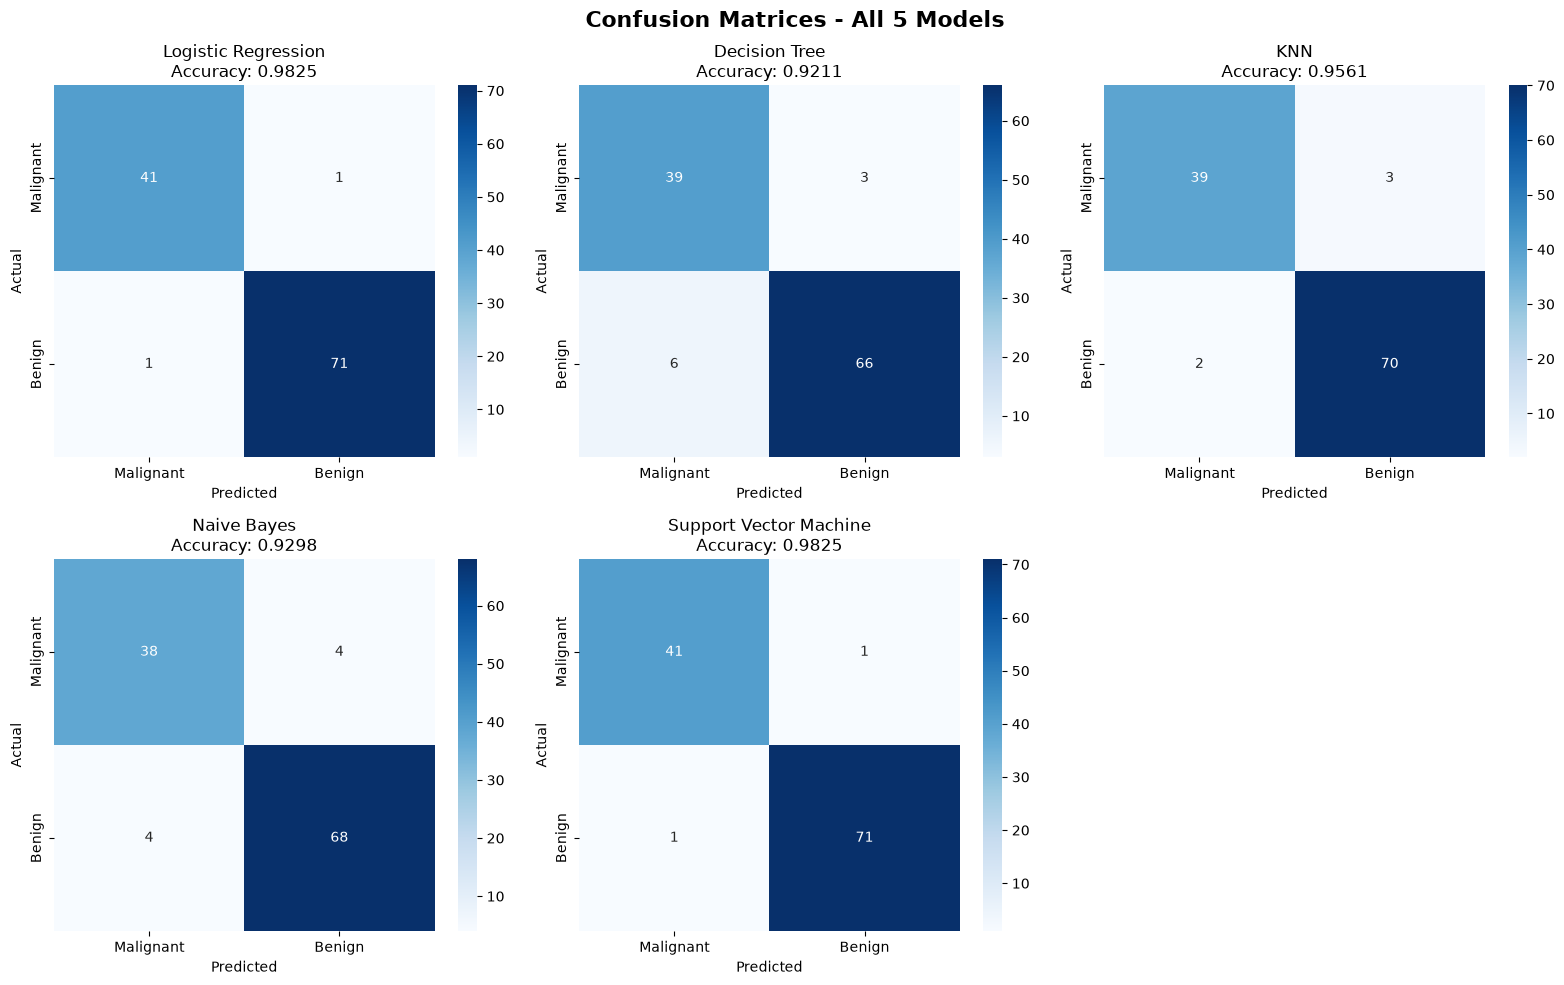

In [23]:
# Plot Confusion Matrices for all 5 models
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

model_list = list(models.items())
for i, (name, model) in enumerate(model_list):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Malignant', 'Benign'],
                yticklabels=['Malignant', 'Benign'])
    axes[i].set_title(f'{name}\nAccuracy: {accuracy_score(y_test, y_pred):.4f}')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

# Hide the unused 6th subplot
axes[5].set_visible(False)

plt.suptitle('Confusion Matrices - All 5 Models', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


## Step 9: Classification Reports

In [24]:
# Print Classification Report for each model
for name, model in models.items():
    y_pred = model.predict(X_test)
    print('=' * 60)
    print(f'Classification Report: {name}')
    print('=' * 60)
    print(classification_report(y_test, y_pred,
                                target_names=['Malignant', 'Benign']))
    print()


Classification Report: Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Classification Report: Decision Tree
              precision    recall  f1-score   support

   Malignant       0.87      0.93      0.90        42
      Benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114


Classification Report: KNN
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       

## Step 10: Metric Comparison Visualizations

cell_40:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


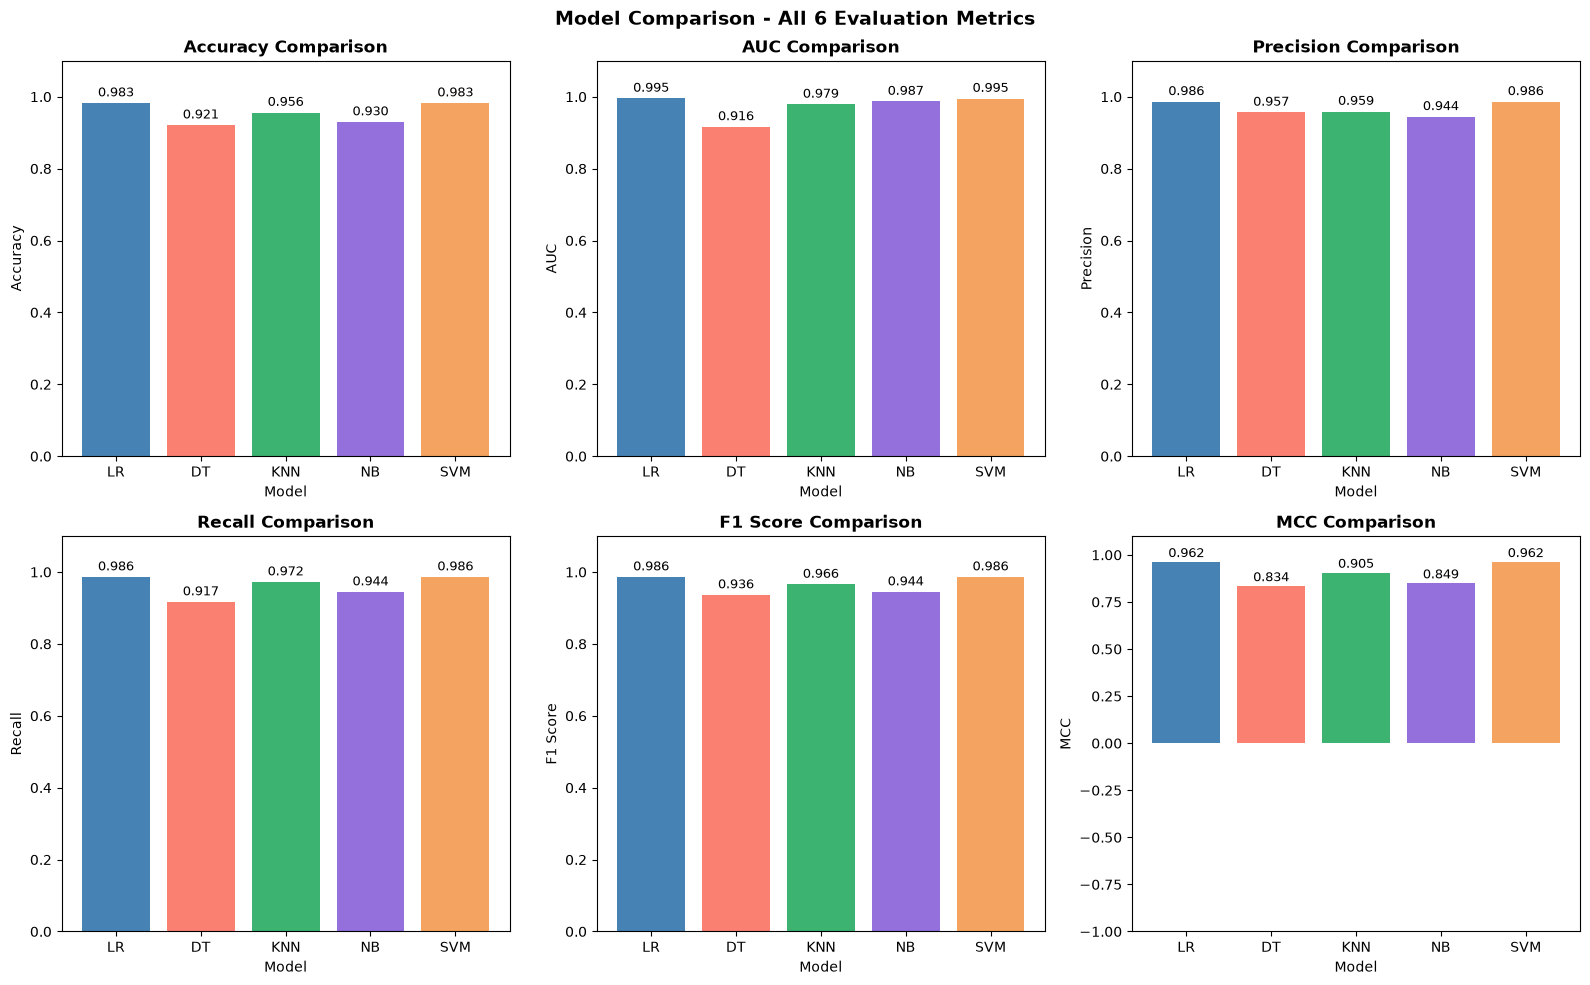

In [25]:
# Bar Plot: All Metrics Comparison
metrics_to_plot = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1 Score', 'MCC']
model_names_short = ['LR', 'DT', 'KNN', 'NB', 'SVM']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
colors = ['steelblue', 'salmon', 'mediumseagreen', 'mediumpurple', 'sandybrown']

for i, metric in enumerate(metrics_to_plot):
    vals = results_df[metric].values
    bars = axes[i].bar(model_names_short, vals, color=colors)
    axes[i].set_title(f'{metric} Comparison', fontweight='bold')
    axes[i].set_ylim(-1 if metric == "MCC" else 0, 1.1)
    axes[i].set_ylabel(metric)
    axes[i].set_xlabel('Model')
    for bar, val in zip(bars, vals):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                     f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Model Comparison - All 6 Evaluation Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


cell_41:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


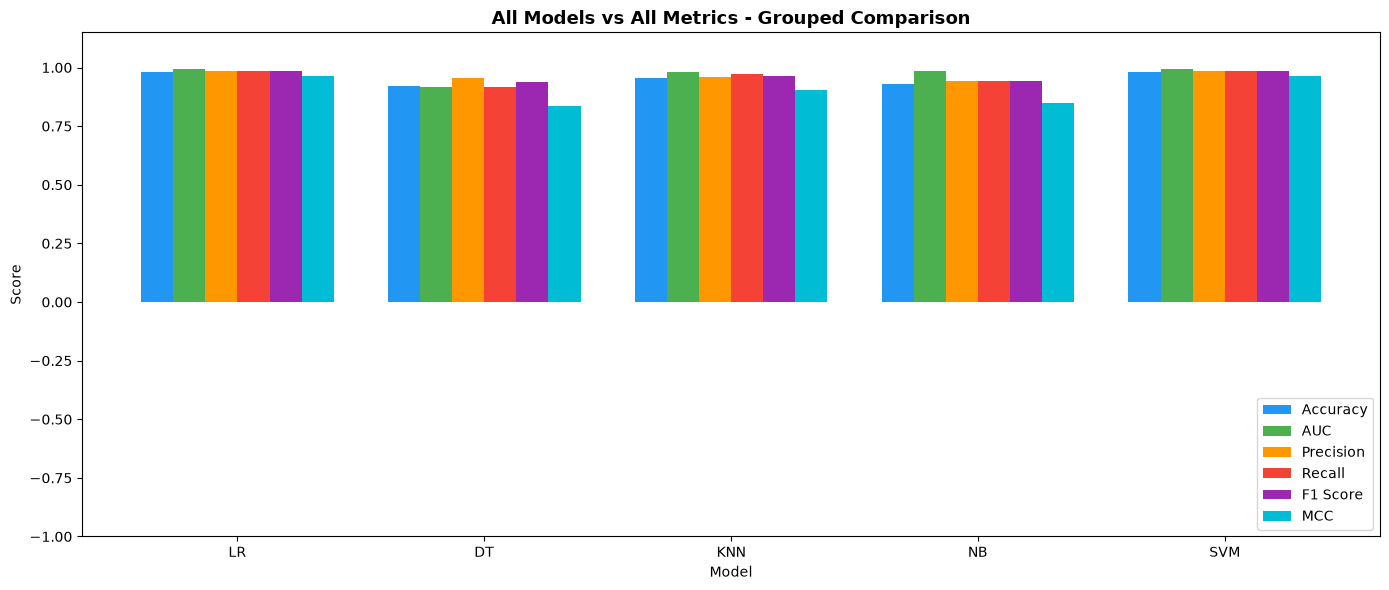

In [26]:
# Grouped Bar Chart for all metrics across models
x = np.arange(len(model_names_short))
width = 0.13
fig, ax = plt.subplots(figsize=(14, 6))
metric_colors = ['#2196F3', '#4CAF50', '#FF9800', '#F44336', '#9C27B0', '#00BCD4']

for j, metric in enumerate(metrics_to_plot):
    vals = results_df[metric].values
    ax.bar(x + j * width, vals, width, label=metric, color=metric_colors[j])

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('All Models vs All Metrics - Grouped Comparison', fontsize=13, fontweight='bold')
ax.set_xticks(x + width * 2.5)
ax.set_xticklabels(model_names_short)
ax.legend(loc='lower right')
ax.set_ylim(-1, 1.15)
plt.tight_layout()
plt.show()


## Step 11: Model Observations

In [27]:
# Observations based on this held-out split, rather than assumed rankings.
for name, row in results_df.iterrows():
    print(f"{name}: accuracy={row['Accuracy']:.4f}, AUC={row['AUC']:.4f}, "
          f"benign recall={row['Recall']:.4f}, MCC={row['MCC']:.4f}")
print('Accuracy leaders:', ', '.join(results_df.index[results_df['Accuracy'] == results_df['Accuracy'].max()]))
print('AUC leader:', results_df['AUC'].idxmax())
print('Results describe one held-out split; they do not establish performance on other populations.')


Logistic Regression: accuracy=0.9825, AUC=0.9954, benign recall=0.9861, MCC=0.9623
Decision Tree: accuracy=0.9211, AUC=0.9163, benign recall=0.9167, MCC=0.8341
KNN: accuracy=0.9561, AUC=0.9788, benign recall=0.9722, MCC=0.9054
Naive Bayes: accuracy=0.9298, AUC=0.9868, benign recall=0.9444, MCC=0.8492
Support Vector Machine: accuracy=0.9825, AUC=0.9950, benign recall=0.9861, MCC=0.9623
Accuracy leaders: Logistic Regression, Support Vector Machine
AUC leader: Logistic Regression
Results describe one held-out split; they do not establish performance on other populations.


In [28]:
# Final Summary
print('\n' + '=' * 70)
print('FINAL SUMMARY')
print('=' * 70)
print(f'Dataset     : Breast Cancer Wisconsin (Diagnostic)')
print(f'Features    : 30')
print(f'Instances   : 569')
print(f'Train Size  : {X_train.shape[0]}')
print(f'Test Size   : {X_test.shape[0]}')
print('\nModels Saved:')
for f in os.listdir('model'):
    print(f'  model/{f}')
print(f'\nTest Data Saved: test_data.csv ({test_df.shape[0]} rows, {test_df.shape[1]} cols)')
print('\nAll models trained, evaluated, and saved successfully!')
print('Ready for Streamlit deployment!')



FINAL SUMMARY
Dataset     : Breast Cancer Wisconsin (Diagnostic)
Features    : 30
Instances   : 569
Train Size  : 455
Test Size   : 114

Models Saved:
  model/svm.pkl
  model/decision_tree.pkl
  model/knn.pkl
  model/logistic_regression.pkl
  model/naive_bayes.pkl

Test Data Saved: test_data.csv (114 rows, 31 cols)

All models trained, evaluated, and saved successfully!
Ready for Streamlit deployment!


---
## Summary Table for README.md

Run the cell below to auto-generate the README comparison table values.

In [29]:
# Print README-ready markdown table
print('| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |')
print('|---|---|---|---|---|---|---|')
for idx, row in results_df.iterrows():
    print(f"| {idx} | {row['Accuracy']} | {row['AUC']} | {row['Precision']} | {row['Recall']} | {row['F1 Score']} | {row['MCC']} |")


| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9825 | 0.9954 | 0.9861 | 0.9861 | 0.9861 | 0.9623 |
| Decision Tree | 0.9211 | 0.9163 | 0.9565 | 0.9167 | 0.9362 | 0.8341 |
| KNN | 0.9561 | 0.9788 | 0.9589 | 0.9722 | 0.9655 | 0.9054 |
| Naive Bayes | 0.9298 | 0.9868 | 0.9444 | 0.9444 | 0.9444 | 0.8492 |
| Support Vector Machine | 0.9825 | 0.995 | 0.9861 | 0.9861 | 0.9861 | 0.9623 |
